## Real Data - Route Simulation from Twist Commands

Validate the RHE on real mission data by simulating a route from the recorded twist commands 
and comparing against the measured odometry.

Median dt: 0.050s, regular diffs: 5160/5190
Using scalar_first = False for quaternion to yaw conversion.
Initial state (x0): [0.01747127 0.00880127 0.13902829]


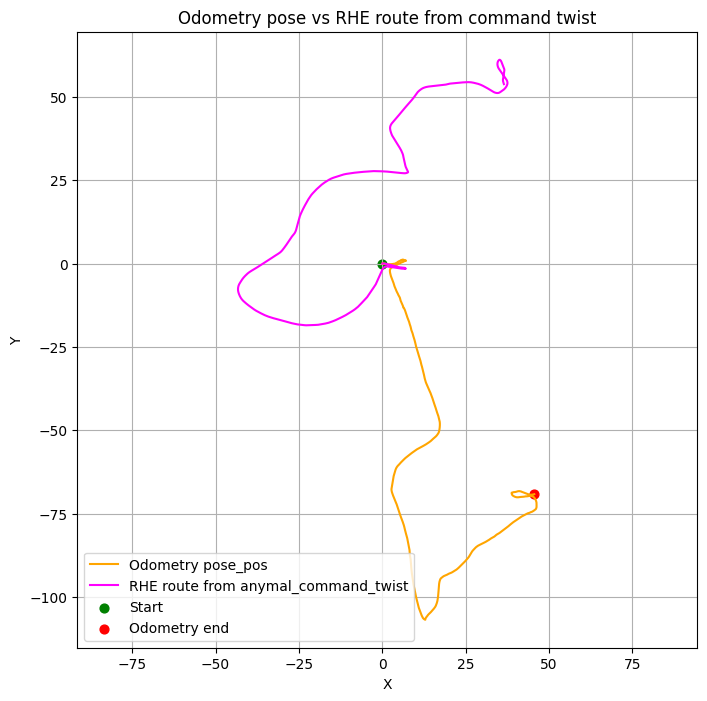

Final position error: 123.292 m
Mean position error: 80.390 m


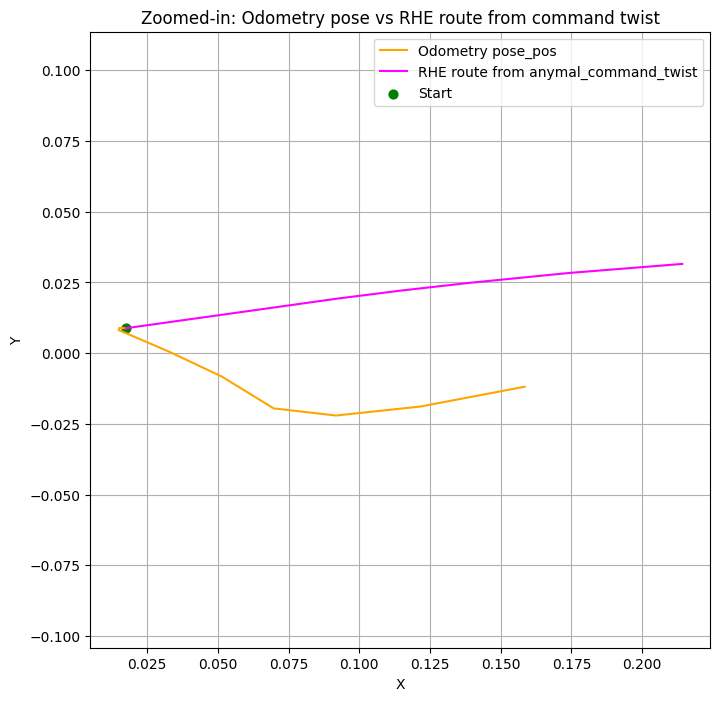

In [1]:
# Route simulation using shared helpers from the package.
# The command twist is treated as a body-frame control input and simulated with RHE.


from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from data_labeling_pipeline.dataset_loader import GrandTourLoader
from data_labeling_pipeline.rhe import RecedingHorizonEstimator

mission = "2024-10-01-11-29-55"

# grand_tour_folder = Path("~/grand_tour_dataset").expanduser()
grand_tour_folder = Path("/datahome/lmertens/grand_tour_dataset")

# Specifc mission with ./data and ./images folder
mission_path = grand_tour_folder / mission


# Initialize the loader with the mission path
loader = GrandTourLoader(mission_path)

shared_ts, U, Z = loader.load_data_shared_timestamps(fill_gaps=True)

x0 = Z[0, :3].copy()  # Initial state from the first measurement (x, y, heading)

# Initial heading = average of the first 100 yaw angles
x0[2] = np.mean(Z[:100, 2])
print(f"Initial state (x0): {x0}")

m = (1, 1, 0)  # Assume ideal parameters for simulation

# Simulate route using RHE
rhe = RecedingHorizonEstimator(N=shared_ts.size, dt=float(np.mean(np.diff(shared_ts))))
command_route = rhe.simulate(x0=x0, U=U, m=m)

plt.figure(figsize=(8, 8))
plt.plot(
    Z[:, 0],
    Z[:, 1],
    label="Odometry pose_pos",
    color="orange",
)
plt.plot(
    command_route[:, 0],
    command_route[:, 1],
    label="RHE route from anymal_command_twist",
    color="magenta",
)
plt.scatter(
    [Z[0, 0]],
    [Z[0, 1]],
    color="green",
    s=40,
    label="Start",
)
plt.scatter(
    [Z[-1, 0]],
    [Z[-1, 1]],
    color="red",
    s=40,
    label="Odometry end",
)
plt.title("Odometry pose vs RHE route from command twist")
plt.xlabel("X")
plt.ylabel("Y")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

route_error = np.linalg.norm(command_route[:, :2] - Z[:, :2], axis=1)
print(f"Final position error: {route_error[-1]:.3f} m")
print(f"Mean position error: {route_error.mean():.3f} m")


ts_limit = 10

# Also plot the same thing, but limited to ts_limit timesteps to zoom in on the start of the route
plt.figure(figsize=(8, 8))
plt.plot(
    Z[:ts_limit, 0],
    Z[:ts_limit, 1],
    label="Odometry pose_pos",
    color="orange",
)
plt.plot(
    command_route[:ts_limit, 0],
    command_route[:ts_limit, 1],
    label="RHE route from anymal_command_twist",
    color="magenta",
)
plt.scatter(
    [Z[0, 0]],
    [Z[0, 1]],
    color="green",
    s=40,
    label="Start",
)
plt.title("Zoomed-in: Odometry pose vs RHE route from command twist")
plt.xlabel("X")
plt.ylabel("Y")
plt.axis("equal")
plt.grid(True)
plt.legend()

Median dt: 0.050s, regular diffs: 5160/5190
Using scalar_first = False for quaternion to yaw conversion.
Initial state (x0): [ 0.01747127  0.00880127 -0.13902829]


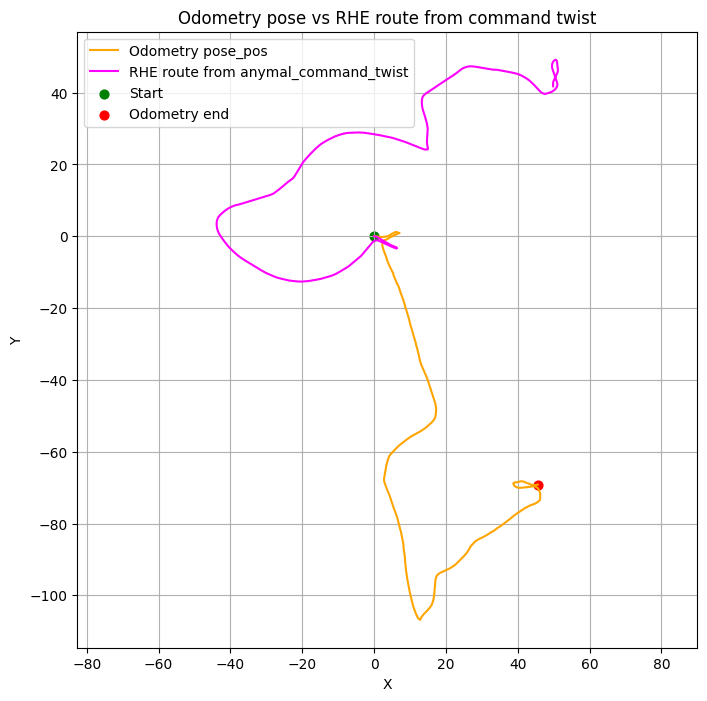

Final position error: 110.962 m
Mean position error: 79.633 m


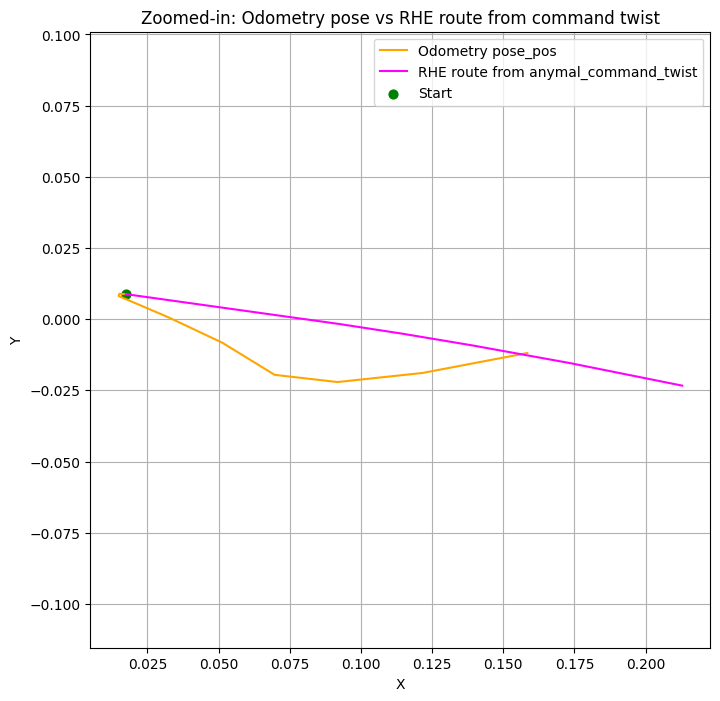

In [2]:
# Route simulation using shared helpers from the package.
# The command twist is treated as a body-frame control input and simulated with RHE.


from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from data_labeling_pipeline.dataset_loader import GrandTourLoader
from data_labeling_pipeline.rhe import RecedingHorizonEstimator

mission = "2024-10-01-11-29-55"

# grand_tour_folder = Path("~/grand_tour_dataset").expanduser()
grand_tour_folder = Path("/datahome/lmertens/grand_tour_dataset")

# Specifc mission with ./data and ./images folder
mission_path = grand_tour_folder / mission


# Initialize the loader with the mission path
loader = GrandTourLoader(mission_path, False)

shared_ts, U, Z = loader.load_data_shared_timestamps(fill_gaps=True)

x0 = Z[0, :3].copy()  # Initial state from the first measurement (x, y, heading)

# Initial heading = average of the first 100 yaw angles
x0[2] = np.mean(Z[:100, 2])
print(f"Initial state (x0): {x0}")

m = (1, 1, 0)  # Assume ideal parameters for simulation

# Simulate route using RHE
rhe = RecedingHorizonEstimator(N=shared_ts.size, dt=float(np.mean(np.diff(shared_ts))))
command_route = rhe.simulate(x0=x0, U=U, m=m)

plt.figure(figsize=(8, 8))
plt.plot(
    Z[:, 0],
    Z[:, 1],
    label="Odometry pose_pos",
    color="orange",
)
plt.plot(
    command_route[:, 0],
    command_route[:, 1],
    label="RHE route from anymal_command_twist",
    color="magenta",
)
plt.scatter(
    [Z[0, 0]],
    [Z[0, 1]],
    color="green",
    s=40,
    label="Start",
)
plt.scatter(
    [Z[-1, 0]],
    [Z[-1, 1]],
    color="red",
    s=40,
    label="Odometry end",
)
plt.title("Odometry pose vs RHE route from command twist")
plt.xlabel("X")
plt.ylabel("Y")
plt.axis("equal")
plt.grid(True)
plt.legend()
plt.show()

route_error = np.linalg.norm(command_route[:, :2] - Z[:, :2], axis=1)
print(f"Final position error: {route_error[-1]:.3f} m")
print(f"Mean position error: {route_error.mean():.3f} m")


ts_limit = 10

# Also plot the same thing, but limited to ts_limit timesteps to zoom in on the start of the route
plt.figure(figsize=(8, 8))
plt.plot(
    Z[:ts_limit, 0],
    Z[:ts_limit, 1],
    label="Odometry pose_pos",
    color="orange",
)
plt.plot(
    command_route[:ts_limit, 0],
    command_route[:ts_limit, 1],
    label="RHE route from anymal_command_twist",
    color="magenta",
)
plt.scatter(
    [Z[0, 0]],
    [Z[0, 1]],
    color="green",
    s=40,
    label="Start",
)
plt.title("Zoomed-in: Odometry pose vs RHE route from command twist")
plt.xlabel("X")
plt.ylabel("Y")
plt.axis("equal")
plt.grid(True)
plt.legend()